# WMC Practical Examination — Statement #11
## Analysis of Channel Interference in the 2.4 GHz Band (WiFi Analyzer app)

**Problem statement.** Using the WiFi Analyzer (open-source) mobile application, analyse the distribution of nearby Wi-Fi networks across different channels in the 2.4 GHz band and identify possible channel interference.
1. Open the Channel Graph View in the application and observe the distribution of nearby Wi-Fi networks across the 2.4 GHz band.
2. Identify channels with maximum and minimum network occupancy and record the channel number, number of networks, and channel status in an observation table.
3. Observe the occurrence of co-channel interference (CCI) and adjacent-channel interference (ACI) from the displayed channel graph.

---
**Aim:** To study how nearby Wi-Fi networks are distributed over the 2.4 GHz channels and to identify co-channel and adjacent-channel interference.

## Theory (brief)
- The 2.4 GHz ISM band (2400–2483.5 MHz) is divided into **13 channels** (India) whose centres are **5 MHz apart** (centre = 2407 + 5·ch MHz), but each Wi-Fi transmission is **20 MHz (≈ 22 MHz) wide**. A channel therefore overlaps its neighbours up to 4 channels away; only **1, 6 and 11** are mutually non-overlapping.
- **Co-Channel Interference (CCI)** – two or more networks on the *same* channel. They hear each other and share airtime through CSMA/CA, so throughput is divided, but they do not corrupt each other's frames as badly.
- **Adjacent-Channel Interference (ACI)** – networks on *different but overlapping* channels (e.g. 1 and 3, or 6 and 9). They cannot decode each other, so they cannot coordinate; their energy appears as noise, causing collisions and retransmissions. **ACI is usually worse than CCI.**
- In the app's **Channel Graph**, every network is drawn as an arch centred on its channel, as wide as its bandwidth and as high as its RSSI. Arches on the same centre ⇒ CCI; overlapping arches with different centres ⇒ ACI.

## Procedure
1. Turn ON Wi-Fi and Location; open **WiFi Analyzer** → menu → **Channel Graph**; select the **2.4 GHz** band.
2. Observe the arches. For every network note its SSID, channel and RSSI (tap/hover or check the *Access Points* list). Optionally open **Channel Rating** to see the app's own rating of each channel.
3. Enter the values in the ✏️ cell below and run the notebook — it redraws the channel graph, counts the networks per channel, classifies channel status and lists all CCI/ACI pairs.

> ⚠️ **The readings currently in this notebook are SAMPLE values** so that every table, graph and conclusion is visible.
> To use your own: open the cell marked **✏️ ENTER YOUR READINGS**, replace the values with what you recorded, set `SAMPLE_DATA = False`, then **Run All**. Every table, graph and conclusion below updates automatically.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from IPython.display import display, Markdown

# ✏️ ENTER YOUR READINGS  (SSID, channel, RSSI dBm, channel width MHz) – 2.4 GHz networks only
SAMPLE_DATA = True
networks = [
    ("Lab-WiFi",            6, -45, 20),
    ("Library_Guest",       6, -68, 20),
    ("Hostel_B_2F",         6, -74, 20),
    ("JioFiber-7C1D",      11, -55, 20),
    ("ACT_Fibernet_9921",  11, -77, 20),
    ("Airtel_Xstream_4F2A", 1, -62, 20),
    ("Redmi Note Hotspot",  1, -84, 20),
    ("TP-Link_3B90",        9, -70, 20),
    ("Canteen_WiFi",        3, -79, 20),
]
df = pd.DataFrame(networks, columns=["SSID", "Channel", "RSSI (dBm)", "Width (MHz)"])
CHANNELS = list(range(1, 14))
print(f"{len(df)} networks on 2.4 GHz" + ("  (SAMPLE DATA)" if SAMPLE_DATA else ""))
if SAMPLE_DATA:
    display(Markdown("<div style='padding:8px;border:2px solid #dd6b20;background:#fffaf0;color:#7b341e'>"
                     "<b>⚠ SAMPLE READINGS</b> – replace with your own measurements and set <code>SAMPLE_DATA = False</code>.</div>"))

9 networks on 2.4 GHz  (SAMPLE DATA)


<div style='padding:8px;border:2px solid #dd6b20;background:#fffaf0;color:#7b341e'><b>⚠ SAMPLE READINGS</b> – replace with your own measurements and set <code>SAMPLE_DATA = False</code>.</div>

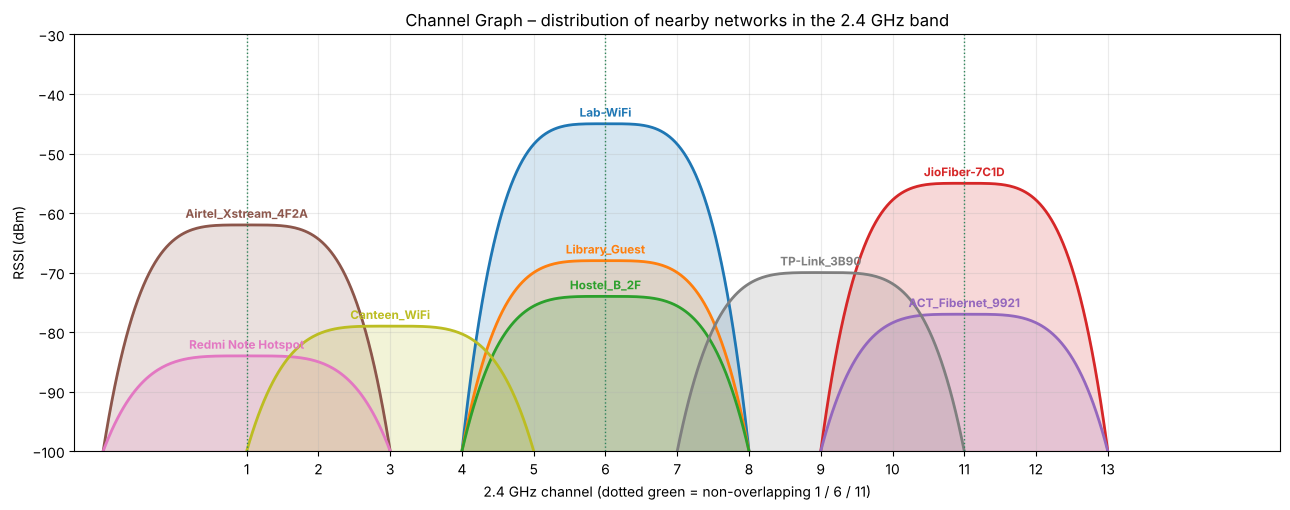

In [2]:
fc = lambda ch: 2407 + 5 * ch            # centre frequency in MHz
fig, ax = plt.subplots(figsize=(13, 5.2))
cmap = plt.get_cmap("tab10")
for i, r in df.reset_index(drop=True).iterrows():
    half = r["Width (MHz)"] / 2
    f = np.linspace(fc(r["Channel"]) - half, fc(r["Channel"]) + half, 200)
    shape = 1 - ((f - fc(r["Channel"])) / half) ** 4          # flat-top arch like the app
    y = -100 + (r["RSSI (dBm)"] + 100) * shape
    col = cmap(i % 10)
    ax.fill_between(f, -100, y, color=col, alpha=0.18); ax.plot(f, y, color=col, lw=2)
    ax.text(fc(r["Channel"]), r["RSSI (dBm)"] + 1.2, r["SSID"], ha="center", fontsize=8.5, color=col, fontweight="bold")
ax.set_xticks([fc(c) for c in CHANNELS]); ax.set_xticklabels(CHANNELS)
for c in (1, 6, 11):
    ax.axvline(fc(c), color="#2f855a", ls=":", lw=1)
ax.set_xlim(fc(1) - 12, fc(13) + 12); ax.set_ylim(-100, -30)
ax.set_xlabel("2.4 GHz channel (dotted green = non-overlapping 1 / 6 / 11)"); ax.set_ylabel("RSSI (dBm)")
ax.set_title("Channel Graph – distribution of nearby networks in the 2.4 GHz band")
ax.grid(alpha=0.25); plt.tight_layout(); plt.show()

### Channel occupancy (all 13 channels)

Channel number,Number of networks,Centre freq (MHz),Channel status
1,2,2412,Busy – CCI; ACI from 1 overlapping network(s)
2,0,2417,MINIMUM occupancy; Free; ACI from 6 overlapping network(s)
3,1,2422,Lightly used; ACI from 5 overlapping network(s)
4,0,2427,MINIMUM occupancy; Free; ACI from 6 overlapping network(s)
5,0,2432,MINIMUM occupancy; Free; ACI from 7 overlapping network(s)
6,3,2437,MAXIMUM occupancy; Congested – heavy CCI; ACI from 2 overlapping network(s)
7,0,2442,MINIMUM occupancy; Free; ACI from 7 overlapping network(s)
8,0,2447,MINIMUM occupancy; Free; ACI from 6 overlapping network(s)
9,1,2452,Lightly used; ACI from 5 overlapping network(s)
10,0,2457,MINIMUM occupancy; Free; ACI from 6 overlapping network(s)


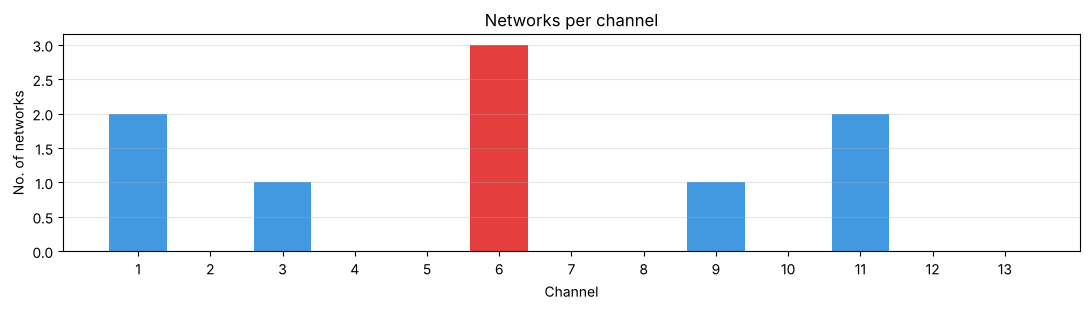

In [3]:
count = df.groupby("Channel").size().reindex(CHANNELS, fill_value=0)

# networks whose 20 MHz spectrum overlaps channel c (|Δch| < 5) but are not on it
def overlapping(c):
    return int(((df["Channel"] - c).abs().between(1, 4)).sum())

mx, mn = count.max(), count.min()
def status(c):
    n = count[c]
    s = []
    if n == mx: s.append("MAXIMUM occupancy")
    if n == mn: s.append("MINIMUM occupancy")
    if n >= 3: s.append("Congested – heavy CCI")
    elif n == 2: s.append("Busy – CCI")
    elif n == 1: s.append("Lightly used")
    else: s.append("Free")
    if overlapping(c): s.append(f"ACI from {overlapping(c)} overlapping network(s)")
    return "; ".join(s)

obs = pd.DataFrame({"Channel number": CHANNELS, "Number of networks": count.values,
                    "Centre freq (MHz)": [fc(c) for c in CHANNELS],
                    "Channel status": [status(c) for c in CHANNELS]})

def hl(row):
    if row["Number of networks"] == mx: return ["background-color:#fed7d7;font-weight:bold"] * len(row)
    if row["Number of networks"] == mn: return ["background-color:#c6f6d5"] * len(row)
    return [""] * len(row)
display(Markdown("### Channel occupancy (all 13 channels)"))
display(obs.style.hide(axis="index").apply(hl, axis=1))

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(CHANNELS, count.values, color=["#e53e3e" if v == mx else "#48bb78" if v == mn else "#4299e1" for v in count.values])
ax.set_xticks(CHANNELS); ax.set_xlabel("Channel"); ax.set_ylabel("No. of networks"); ax.set_title("Networks per channel")
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

In [4]:
max_ch = [c for c in CHANNELS if count[c] == mx]
min_ch = [c for c in CHANNELS if count[c] == mn]
used_min = count[count > 0].min()
used_min_ch = [c for c in CHANNELS if count[c] == used_min]
summary = pd.DataFrame([
    {"Observation": "Maximum occupancy", "Channel number": ", ".join(map(str, max_ch)), "Number of networks": mx,
     "Channel status": "Congested – highest co-channel interference" if mx >= 3 else "Busy"},
    {"Observation": "Minimum occupancy (among used channels)", "Channel number": ", ".join(map(str, used_min_ch)),
     "Number of networks": used_min, "Channel status": "Lightly used – low CCI"},
    {"Observation": "Minimum occupancy (all channels)", "Channel number": ", ".join(map(str, min_ch)), "Number of networks": mn,
     "Channel status": "Free – no network on this centre channel" if mn == 0 else "Least used"},
])
display(Markdown("### Observation table – maximum and minimum occupancy"))
display(summary.style.hide(axis="index"))

### Observation table – maximum and minimum occupancy

Observation,Channel number,Number of networks,Channel status
Maximum occupancy,6,3,Congested – highest co-channel interference
Minimum occupancy (among used channels),"3, 9",1,Lightly used – low CCI
Minimum occupancy (all channels),"2, 4, 5, 7, 8, 10, 12, 13",0,Free – no network on this centre channel


In [5]:
cci, aci = [], []
for (i, a), (j, b) in combinations(df.iterrows(), 2):
    d = abs(a["Channel"] - b["Channel"])
    if d == 0:
        cci.append({"Channel": a["Channel"], "Network 1": a["SSID"], "Network 2": b["SSID"],
                    "RSSI": f"{a['RSSI (dBm)']} / {b['RSSI (dBm)']} dBm"})
    elif d < 5:
        overlap = 20 - 5 * d
        aci.append({"Channels": f"{a['Channel']} ↔ {b['Channel']}", "Network 1": a["SSID"], "Network 2": b["SSID"],
                    "Channel gap": d, "Spectral overlap (MHz)": overlap})
display(Markdown(f"### Co-Channel Interference (CCI): {len(cci)} pair(s)"))
display(pd.DataFrame(cci).style.hide(axis="index") if cci else Markdown("_No two networks share a channel._"))
display(Markdown(f"### Adjacent-Channel Interference (ACI): {len(aci)} pair(s)"))
display(pd.DataFrame(aci).sort_values("Spectral overlap (MHz)", ascending=False).style.hide(axis="index") if aci
        else Markdown("_No partially-overlapping channels._"))

# interference score for the three non-overlapping channels: sum of linear power of networks overlapping them
def score(c):
    near = df[(df["Channel"] - c).abs() < 5]
    return (10 ** (near["RSSI (dBm)"] / 10) * (1 - (near["Channel"] - c).abs() / 5)).sum()
best = min((1, 6, 11), key=score)
print(f"Least interfered of the non-overlapping channels 1/6/11 → channel {best}")

### Co-Channel Interference (CCI): 5 pair(s)

Channel,Network 1,Network 2,RSSI
6,Lab-WiFi,Library_Guest,-45 / -68 dBm
6,Lab-WiFi,Hostel_B_2F,-45 / -74 dBm
6,Library_Guest,Hostel_B_2F,-68 / -74 dBm
11,JioFiber-7C1D,ACT_Fibernet_9921,-55 / -77 dBm
1,Airtel_Xstream_4F2A,Redmi Note Hotspot,-62 / -84 dBm


### Adjacent-Channel Interference (ACI): 10 pair(s)

Channels,Network 1,Network 2,Channel gap,Spectral overlap (MHz)
1 ↔ 3,Airtel_Xstream_4F2A,Canteen_WiFi,2,10
1 ↔ 3,Redmi Note Hotspot,Canteen_WiFi,2,10
11 ↔ 9,ACT_Fibernet_9921,TP-Link_3B90,2,10
11 ↔ 9,JioFiber-7C1D,TP-Link_3B90,2,10
6 ↔ 3,Lab-WiFi,Canteen_WiFi,3,5
6 ↔ 9,Lab-WiFi,TP-Link_3B90,3,5
6 ↔ 3,Hostel_B_2F,Canteen_WiFi,3,5
6 ↔ 9,Hostel_B_2F,TP-Link_3B90,3,5
6 ↔ 3,Library_Guest,Canteen_WiFi,3,5
6 ↔ 9,Library_Guest,TP-Link_3B90,3,5


Least interfered of the non-overlapping channels 1/6/11 → channel 1


## Result & Conclusion
The Channel Graph shows that nearby networks are **not evenly spread**: most of them crowd onto the default channels **1, 6 and 11**, with the maximum occupancy on the channel highlighted in red above, while several channels in between carry no network at all.

- **Co-channel interference (CCI)** is observed wherever two or more arches share the same centre channel (listed above). These networks share airtime, so each one gets a smaller share of the throughput.
- **Adjacent-channel interference (ACI)** is observed where arches with different centres overlap — typically networks configured on channels other than 1/6/11 (e.g. 3 or 9), which overlap two neighbouring groups at once. Because such networks cannot decode each other, ACI causes collisions and retransmissions and is more harmful than CCI.

**Conclusion:** The 2.4 GHz band has only three non-overlapping channels, so congestion and interference are common. Interference is minimised by using only channels 1, 6 or 11, choosing the least occupied of them (the notebook names the best one), reducing transmit power where possible, and moving capable devices to the 5 GHz band.